In [1]:
# import, seed, device, dan konfigurasi
import os
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from skimage.metrics import structural_similarity, peak_signal_noise_ratio
from sklearn.metrics import mean_squared_error

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from torchvision.utils import make_grid

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 128
LATENT_DIM = 64
GAN_LATENT_DIM = 100
DDPM_TIMESTEPS = 100
EPOCHS_AE = 10
EPOCHS_SAE = 10
EPOCHS_VAE = 10
EPOCHS_GAN = 10
EPOCHS_DCGAN = 10
EPOCHS_DDPM = 5
EPOCHS_MLP = 10
EPOCHS_FROZEN_DECODER = 10

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Fashion-MNIST dan split train/validation/test 80/10/10
transform = transforms.ToTensor()
train_source = datasets.FashionMNIST("./data", train=True, download=True, transform=transform)
test_source = datasets.FashionMNIST("./data", train=False, download=True, transform=transform)
full_dataset = torch.utils.data.ConcatDataset([train_source, test_source])

n_total = len(full_dataset)
n_train = int(0.8 * n_total)
n_val = int(0.1 * n_total)
n_test = n_total - n_train - n_val
train_dataset, val_dataset, test_dataset = random_split(
    full_dataset, [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(SEED)
)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

100%|██████████| 26.4M/26.4M [00:12<00:00, 2.20MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 99.1kB/s]
100%|██████████| 4.42M/4.42M [00:04<00:00, 1.04MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 19.9MB/s]


In [3]:
# Define Arsitektur
class VanillaAutoencoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, latent_dim), nn.ReLU())
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid())
    def encode(self, x):
        return self.encoder(x)
    def decode(self, z):
        return self.decoder(z).reshape(-1, 1, 28, 28)
    def forward(self, x):
        return self.decode(self.encode(x))


class SparseAutoencoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, latent_dim), nn.ReLU())
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid())
    def encode(self, x):
        return self.encoder(x)
    def decode(self, z):
        return self.decoder(z).reshape(-1, 1, 28, 28)
    def forward(self, x):
        z = self.encode(x)
        return self.decode(z), z


class VariationalAutoencoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU())
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid())
    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)
    def reparameterize(self, mu, logvar):
        return mu + torch.randn_like(logvar) * torch.exp(0.5 * logvar)
    def decode(self, z):
        return self.decoder(z).reshape(-1, 1, 28, 28)
    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decode(self.reparameterize(mu, logvar)), mu, logvar


class Generator(nn.Module):
    def __init__(self, latent_dim=100):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(latent_dim, 256), nn.LeakyReLU(0.2), nn.Linear(256, 512), nn.LeakyReLU(0.2), nn.Linear(512, 784), nn.Tanh())
    def forward(self, z):
        return self.network(z).reshape(-1, 1, 28, 28)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(nn.Flatten(), nn.Linear(784, 512), nn.LeakyReLU(0.2), nn.Linear(512, 256), nn.LeakyReLU(0.2), nn.Linear(256, 1))
    def forward(self, x):
        return self.network(x)


class DCGANGenerator(nn.Module):
    def __init__(self, latent_dim=100):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(latent_dim, 128*7*7), nn.BatchNorm1d(128*7*7), nn.ReLU(True),
            nn.Unflatten(1, (128, 7, 7)),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh()
        )
    def forward(self, z):
        return self.network(z)


class DCGANDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),
            nn.Flatten(), nn.Linear(128*7*7, 1)
        )
    def forward(self, x):
        return self.network(x)


class DDPM(nn.Module):
    def __init__(self, timesteps=100):
        super().__init__()
        self.time_embedding = nn.Embedding(timesteps, 32)
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 32, 3, padding=1)
        self.conv4 = nn.Conv2d(32, 1, 3, padding=1)
    def forward(self, x, t):
        h = F.relu(self.conv1(x))
        h = h + self.time_embedding(t).unsqueeze(-1).unsqueeze(-1)
        h = F.relu(self.conv2(h))
        h = F.relu(self.conv3(h))
        return self.conv4(h)


class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 64), nn.ReLU())
        self.classifier = nn.Linear(64, 10)
    def forward(self, x):
        return self.classifier(self.features(x))
    def extract_features(self, x):
        return self.features(x)


class FrozenLatentDecoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.decoder = nn.Sequential(nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid())
    def forward(self, z):
        return self.decoder(z).reshape(-1, 1, 28, 28)

In [4]:
# Training dan evaluasi
def train_autoencoder(model, name, epochs, sparse_lambda=None):
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    train_losses, val_losses, epoch_times = [], [], []
    criterion = nn.MSELoss()
    for epoch in range(epochs):
        start = time.perf_counter()
        model.train()
        total = 0.0
        for images, _ in tqdm(train_loader, desc=f"{name} {epoch+1}/{epochs}", leave=False):
            images = images.to(device)
            optimizer.zero_grad()
            if sparse_lambda is None:
                reconstructed = model(images)
                loss = criterion(reconstructed, images)
            else:
                reconstructed, z = model(images)
                loss = criterion(reconstructed, images) + sparse_lambda * z.abs().mean()
            loss.backward()
            optimizer.step()
            total += loss.item() * images.size(0)
        train_losses.append(total / len(train_dataset))
        model.eval()
        total_val = 0.0
        with torch.no_grad():
            for images, _ in val_loader:
                images = images.to(device)
                if sparse_lambda is None:
                    reconstructed = model(images)
                    loss = criterion(reconstructed, images)
                else:
                    reconstructed, z = model(images)
                    loss = criterion(reconstructed, images) + sparse_lambda * z.abs().mean()
                total_val += loss.item() * images.size(0)
        val_losses.append(total_val / len(val_dataset))
        epoch_times.append(time.perf_counter() - start)
    torch.save(model.state_dict(), RESULTS_DIR / f"{name}.pth")
    return train_losses, val_losses, epoch_times


def evaluate_reconstruction(model, mode="ae"):
    model.eval()
    originals, reconstructions = [], []
    with torch.no_grad():
        for images, _ in test_loader:
            images = images.to(device)
            if mode == "sparse":
                reconstructed, _ = model(images)
            elif mode == "vae":
                reconstructed, _, _ = model(images)
            else:
                reconstructed = model(images)
            originals.append(images.cpu())
            reconstructions.append(reconstructed.cpu())
    originals, reconstructions = torch.cat(originals), torch.cat(reconstructions)
    mse = mean_squared_error(originals.numpy().ravel(), reconstructions.numpy().ravel())
    psnr = peak_signal_noise_ratio(originals.numpy(), reconstructions.numpy(), data_range=1.0)
    ssim = np.mean([
        structural_similarity(originals[i, 0].numpy(), reconstructions[i, 0].numpy(), data_range=1.0)
        for i in range(len(originals))
    ])
    return mse, psnr, ssim, originals, reconstructions


def measure_latency(fn, warmup=10, runs=100):
    for _ in range(warmup):
        fn()
    if device.type == "mps":
        torch.mps.synchronize()
    start = time.perf_counter()
    for _ in range(runs):
        fn()
    if device.type == "mps":
        torch.mps.synchronize()
    return (time.perf_counter() - start) * 1000 / runs

In [5]:
# Training Vanilla AE, Sparse AE, dan VAE
model_ae = VanillaAutoencoder(LATENT_DIM).to(device)
train_loss_ae, val_loss_ae, time_ae = train_autoencoder(model_ae, "vanilla_ae", EPOCHS_AE)

model_sae = SparseAutoencoder(LATENT_DIM).to(device)
train_loss_sae, val_loss_sae, time_sae = train_autoencoder(model_sae, "sparse_ae", EPOCHS_SAE, sparse_lambda=1e-4)

def train_vae(model, epochs):
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    train_losses, val_losses, epoch_times = [], [], []
    for epoch in range(epochs):
        start = time.perf_counter()
        model.train()
        total = 0.0
        for images, _ in tqdm(train_loader, desc=f"VAE {epoch+1}/{epochs}", leave=False):
            images = images.to(device)
            optimizer.zero_grad()
            reconstructed, mu, logvar = model(images)
            recon_loss = F.mse_loss(reconstructed, images)
            kl_loss = -0.5 * torch.mean(torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1)) / 784
            loss = recon_loss + kl_loss
            loss.backward()
            optimizer.step()
            total += loss.item() * images.size(0)
        train_losses.append(total / len(train_dataset))
        model.eval()
        val_total = 0.0
        with torch.no_grad():
            for images, _ in val_loader:
                images = images.to(device)
                reconstructed, mu, logvar = model(images)
                recon_loss = F.mse_loss(reconstructed, images)
                kl_loss = -0.5 * torch.mean(torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1)) / 784
                val_total += (recon_loss + kl_loss).item() * images.size(0)
        val_losses.append(val_total / len(val_dataset))
        epoch_times.append(time.perf_counter() - start)
    torch.save(model.state_dict(), RESULTS_DIR / "vae.pth")
    return train_losses, val_losses, epoch_times

model_vae = VariationalAutoencoder(LATENT_DIM).to(device)
train_loss_vae, val_loss_vae, time_vae = train_vae(model_vae, EPOCHS_VAE)

In [6]:
# Training Vanilla GAN dan DCGAN
def train_gan(generator, discriminator, epochs, name):
    criterion = nn.BCEWithLogitsLoss()
    opt_g = optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
    opt_d = optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))
    g_losses, d_losses, epoch_times = [], [], []
    for epoch in range(epochs):
        start = time.perf_counter()
        generator.train()
        discriminator.train()
        sum_g, sum_d, count = 0.0, 0.0, 0
        for images, _ in tqdm(train_loader, desc=f"{name} {epoch+1}/{epochs}", leave=False):
            images = images.to(device) * 2 - 1
            batch = images.size(0)
            real = torch.ones(batch, 1, device=device)
            fake = torch.zeros(batch, 1, device=device)

            opt_d.zero_grad()
            real_loss = criterion(discriminator(images), real)
            noise = torch.randn(batch, GAN_LATENT_DIM, device=device)
            fake_images = generator(noise)
            fake_loss = criterion(discriminator(fake_images.detach()), fake)
            d_loss = real_loss + fake_loss
            d_loss.backward()
            opt_d.step()

            opt_g.zero_grad()
            noise = torch.randn(batch, GAN_LATENT_DIM, device=device)
            generated = generator(noise)
            g_loss = criterion(discriminator(generated), real)
            g_loss.backward()
            opt_g.step()

            sum_g += g_loss.item() * batch
            sum_d += d_loss.item() * batch
            count += batch
        g_losses.append(sum_g / count)
        d_losses.append(sum_d / count)
        epoch_times.append(time.perf_counter() - start)
    torch.save(generator.state_dict(), RESULTS_DIR / f"{name}_generator.pth")
    torch.save(discriminator.state_dict(), RESULTS_DIR / f"{name}_discriminator.pth")
    return g_losses, d_losses, epoch_times

generator_gan = Generator(GAN_LATENT_DIM).to(device)
discriminator_gan = Discriminator().to(device)
g_loss_history, d_loss_history, time_gan = train_gan(generator_gan, discriminator_gan, EPOCHS_GAN, "vanilla_gan")

generator_dcgan = DCGANGenerator(GAN_LATENT_DIM).to(device)
discriminator_dcgan = DCGANDiscriminator().to(device)
g_loss_dcgan, d_loss_dcgan, time_dcgan = train_gan(generator_dcgan, discriminator_dcgan, EPOCHS_DCGAN, "dcgan")

In [7]:
# Training DDPM
timesteps = DDPM_TIMESTEPS
betas = torch.linspace(1e-4, 0.02, timesteps, device=device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

model_ddpm = DDPM(timesteps).to(device)
optimizer_ddpm = optim.Adam(model_ddpm.parameters(), lr=0.001)
train_loss_ddpm, time_ddpm = [], []
for epoch in range(EPOCHS_DDPM):
    start = time.perf_counter()
    model_ddpm.train()
    total = 0.0
    for images, _ in tqdm(train_loader, desc=f"DDPM {epoch+1}/{EPOCHS_DDPM}", leave=False):
        x0 = images.to(device) * 2 - 1
        batch = x0.size(0)
        t = torch.randint(0, timesteps, (batch,), device=device)
        noise = torch.randn_like(x0)
        alpha_bar_t = alpha_bars[t].view(batch, 1, 1, 1)
        xt = torch.sqrt(alpha_bar_t) * x0 + torch.sqrt(1 - alpha_bar_t) * noise
        loss = F.mse_loss(model_ddpm(xt, t), noise)
        optimizer_ddpm.zero_grad()
        loss.backward()
        optimizer_ddpm.step()
        total += loss.item() * batch
    train_loss_ddpm.append(total / len(train_dataset))
    time_ddpm.append(time.perf_counter() - start)
torch.save(model_ddpm.state_dict(), RESULTS_DIR / "ddpm.pth")

In [8]:
# Training MLP classifier dan frozen latent decoder
model_mlp = MLPClassifier().to(device)
optimizer_mlp = optim.Adam(model_mlp.parameters(), lr=0.001)
criterion_mlp = nn.CrossEntropyLoss()
train_loss_mlp, val_loss_mlp = [], []
for epoch in range(EPOCHS_MLP):
    model_mlp.train()
    total = 0.0
    for images, labels in tqdm(train_loader, desc=f"MLP {epoch+1}/{EPOCHS_MLP}", leave=False):
        images, labels = images.to(device), labels.to(device)
        optimizer_mlp.zero_grad()
        loss = criterion_mlp(model_mlp(images), labels)
        loss.backward()
        optimizer_mlp.step()
        total += loss.item() * images.size(0)
    train_loss_mlp.append(total / len(train_dataset))
    model_mlp.eval()
    val_total = 0.0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            val_total += criterion_mlp(model_mlp(images), labels).item() * images.size(0)
    val_loss_mlp.append(val_total / len(val_dataset))

model_mlp.eval()
correct, total = 0, 0
latent_test = []
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        correct += (model_mlp(images).argmax(1) == labels).sum().item()
        total += labels.size(0)
        latent_test.append(model_mlp.extract_features(images).cpu())
accuracy_mlp = correct / total
latent_test = torch.cat(latent_test)
torch.save(model_mlp.state_dict(), RESULTS_DIR / "mlp_classifier.pth")

for parameter in model_mlp.parameters():
    parameter.requires_grad = False
frozen_decoder = FrozenLatentDecoder().to(device)
optimizer_decoder = optim.Adam(frozen_decoder.parameters(), lr=0.001)
train_loss_decoder = []
for epoch in range(EPOCHS_FROZEN_DECODER):
    frozen_decoder.train()
    total_loss = 0.0
    for images, _ in tqdm(train_loader, desc=f"Frozen decoder {epoch+1}/{EPOCHS_FROZEN_DECODER}", leave=False):
        images = images.to(device)
        with torch.no_grad():
            z = model_mlp.extract_features(images)
        reconstructed = frozen_decoder(z)
        loss = F.mse_loss(reconstructed, images)
        optimizer_decoder.zero_grad()
        loss.backward()
        optimizer_decoder.step()
        total_loss += loss.item() * images.size(0)
    train_loss_decoder.append(total_loss / len(train_dataset))
torch.save(frozen_decoder.state_dict(), RESULTS_DIR / "frozen_latent_decoder.pth")

In [9]:
# Evaluasi MLP dan rekonstruksi
mse_ae, psnr_ae, ssim_ae, originals, recon_ae = evaluate_reconstruction(model_ae)
mse_sae, psnr_sae, ssim_sae, _, recon_sae = evaluate_reconstruction(model_sae, "sparse")
mse_vae, psnr_vae, ssim_vae, _, recon_vae = evaluate_reconstruction(model_vae, "vae")

model_mlp.eval()
correct, total = 0, 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        correct += (model_mlp(images).argmax(1) == labels).sum().item()
        total += labels.size(0)
accuracy_mlp = correct / total

mlp_originals, mlp_recons = [], []
frozen_decoder.eval()
with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(device)
        mlp_originals.append(images.cpu())
        mlp_recons.append(frozen_decoder(model_mlp.extract_features(images)).cpu())
mlp_originals, mlp_recons = torch.cat(mlp_originals), torch.cat(mlp_recons)
mse_mlp_decoder = mean_squared_error(mlp_originals.numpy().ravel(), mlp_recons.numpy().ravel())
psnr_mlp_decoder = peak_signal_noise_ratio(mlp_originals.numpy(), mlp_recons.numpy(), data_range=1.0)
ssim_mlp_decoder = np.mean([structural_similarity(mlp_originals[i,0].numpy(), mlp_recons[i,0].numpy(), data_range=1.0) for i in range(len(mlp_originals))])

metrics_df = pd.DataFrame([
    {"Model":"Vanilla AE","Test MSE":mse_ae,"Test PSNR":psnr_ae,"Test SSIM":ssim_ae},
    {"Model":"Sparse AE","Test MSE":mse_sae,"Test PSNR":psnr_sae,"Test SSIM":ssim_sae},
    {"Model":"VAE","Test MSE":mse_vae,"Test PSNR":psnr_vae,"Test SSIM":ssim_vae},
    {"Model":"Frozen MLP Decoder","Test MSE":mse_mlp_decoder,"Test PSNR":psnr_mlp_decoder,"Test SSIM":ssim_mlp_decoder}
])
metrics_df

,Model,Test MSE,Test PSNR,Test SSIM
0,Vanilla AE,0.010431,19.816664,0.752431
1,Sparse AE,0.009682,20.140327,0.761049
2,VAE,0.022667,16.446037,0.574969
3,Frozen MLP Decoder,0.018032,17.439597,0.636691


In [54]:
acc = float(accuracy_mlp)

if acc <= 1:
    acc *= 100

print(f"MLP Test Accuracy: {acc:.2f}%")

MLP Test Accuracy: 88.91%


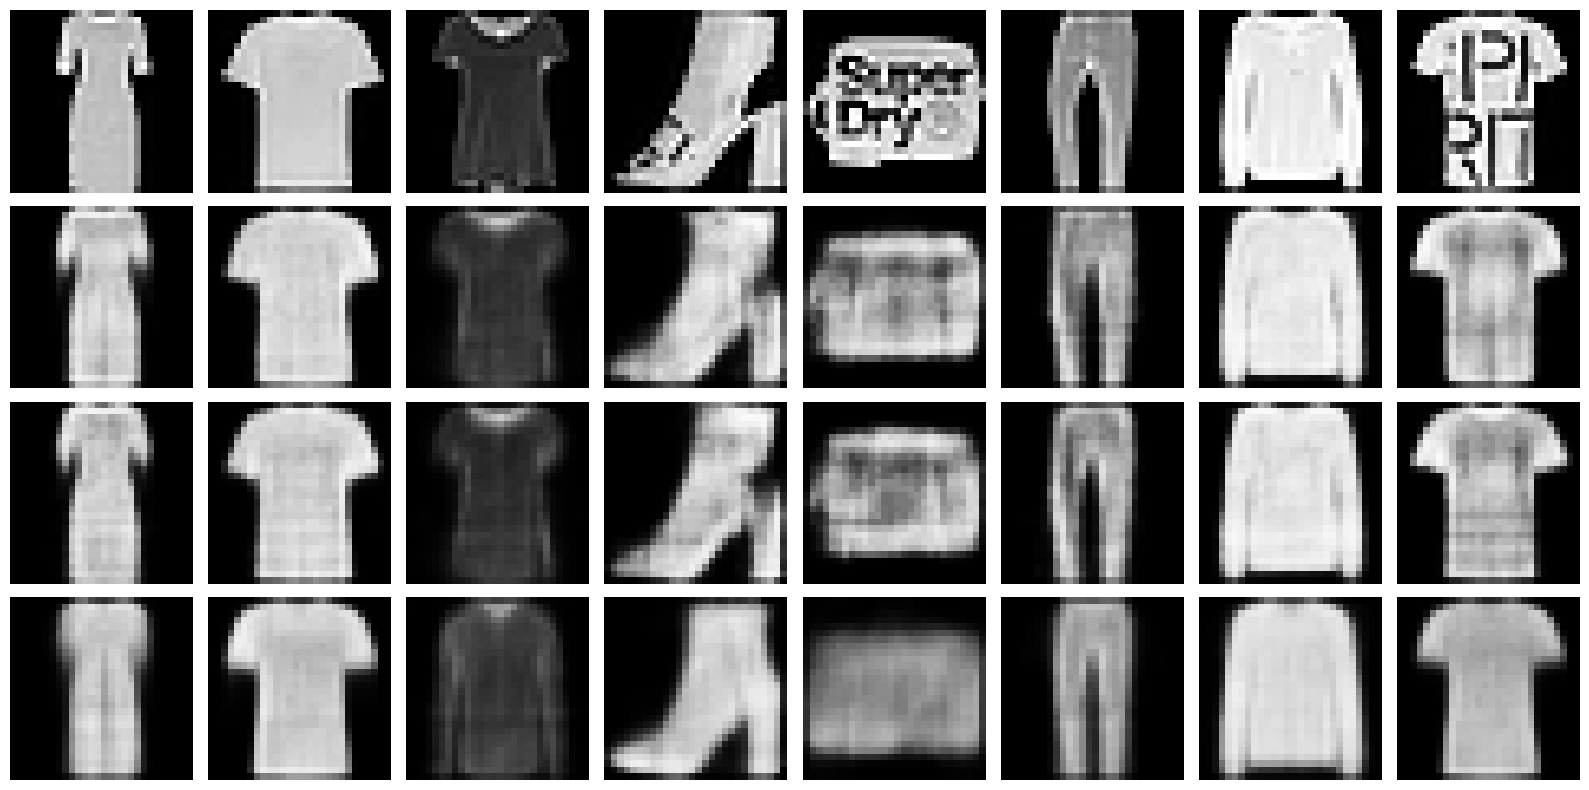

In [10]:
# Fig 1
fig, axes = plt.subplots(4, 8, figsize=(16, 8))
rows = [originals[:8], recon_ae[:8], recon_sae[:8], recon_vae[:8]]
labels = ["Original", "Vanilla AE", "Sparse AE", "VAE"]
for r in range(4):
    for c in range(8):
        axes[r,c].imshow(rows[r][c,0], cmap="gray", vmin=0, vmax=1)
        axes[r,c].axis("off")
        if c == 0:
            axes[r,c].set_ylabel(labels[r])
plt.tight_layout()
plt.savefig(RESULTS_DIR / "figure1_reconstructions.png", dpi=200, bbox_inches="tight")
plt.show()

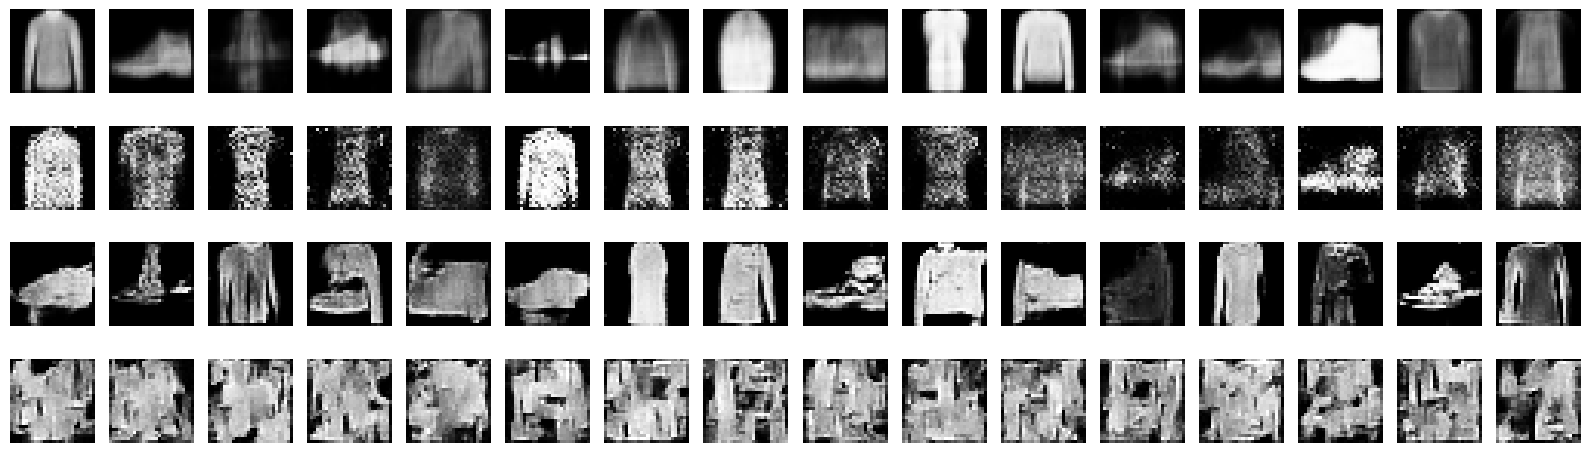

In [11]:
# Fig 2
@torch.no_grad()
def sample_vae(n=16):
    return model_vae.decode(torch.randn(n, LATENT_DIM, device=device)).cpu()

@torch.no_grad()
def sample_gan(generator, n=16):
    generator.eval()
    return ((generator(torch.randn(n, GAN_LATENT_DIM, device=device)) + 1) / 2).clamp(0,1).cpu()

@torch.no_grad()
def sample_ddpm(n=16, save_trajectory=False):
    model_ddpm.eval()
    x = torch.randn(n,1,28,28,device=device)
    trajectory = [x.cpu()] if save_trajectory else None
    for t in reversed(range(timesteps)):
        t_batch = torch.full((n,),t,device=device,dtype=torch.long)
        pred_noise = model_ddpm(x,t_batch)
        alpha_t, alpha_bar_t, beta_t = alphas[t], alpha_bars[t], betas[t]
        x = (x - ((1-alpha_t)/torch.sqrt(1-alpha_bar_t))*pred_noise) / torch.sqrt(alpha_t)
        if t > 0:
            x = x + torch.sqrt(beta_t)*torch.randn_like(x)
        if save_trajectory and (t % max(1,timesteps//8) == 0 or t == 0):
            trajectory.append(x.detach().cpu())
    x = ((x+1)/2).clamp(0,1).cpu()
    return (x, trajectory) if save_trajectory else x

samples = [
    ("VAE", sample_vae(16)),
    ("Vanilla GAN", sample_gan(generator_gan,16)),
    ("DCGAN", sample_gan(generator_dcgan,16)),
    ("DDPM", sample_ddpm(16))
]
fig, axes = plt.subplots(4,16,figsize=(16,5))
for r,(name,batch) in enumerate(samples):
    for c in range(16):
        axes[r,c].imshow(batch[c,0],cmap="gray",vmin=0,vmax=1)
        axes[r,c].axis("off")
    axes[r,0].set_ylabel(name)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "figure2_random_samples.png",dpi=200,bbox_inches="tight")
plt.show()

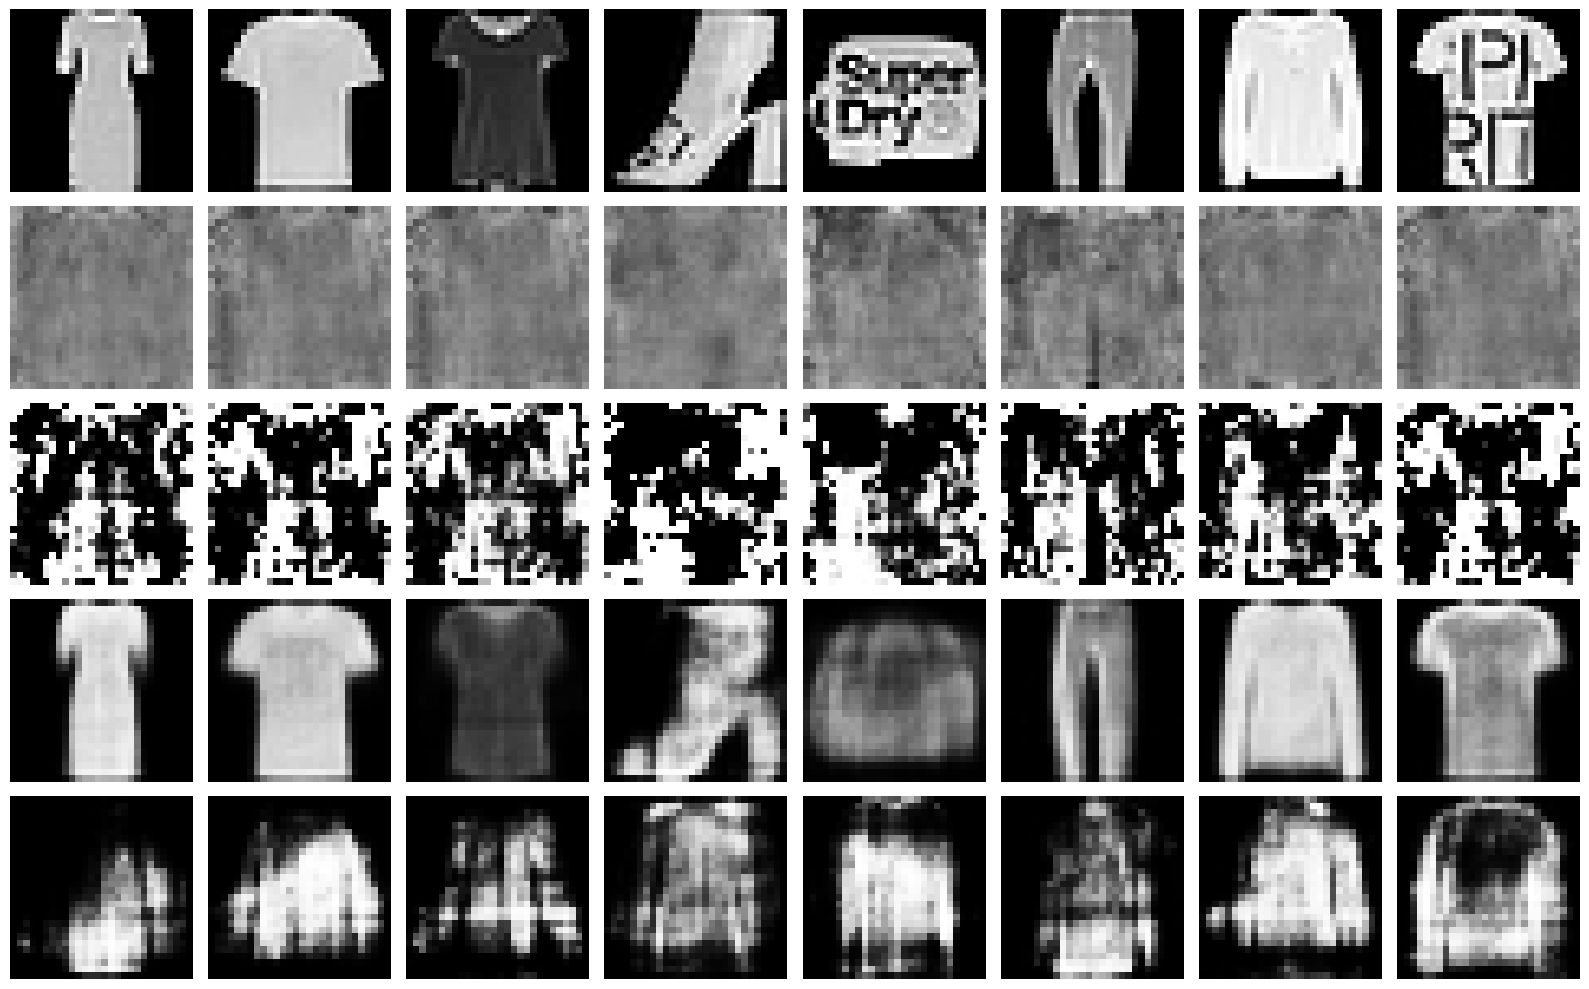

In [12]:
# Fig 3
model_mlp.eval()
frozen_decoder.eval()
batch_images, batch_labels = next(iter(test_loader))
batch_images = batch_images.to(device)
batch_labels = batch_labels.to(device)
with torch.no_grad():
    z_mlp = model_mlp.extract_features(batch_images)
    one_hot = F.one_hot(batch_labels, num_classes=10).float()
    z_class_back = torch.relu(one_hot @ model_mlp.classifier.weight)
    h_class_back = torch.relu(z_class_back @ model_mlp.features[3].weight)
    x_class_back = torch.sigmoid(h_class_back @ model_mlp.features[1].weight).reshape(-1,1,28,28)
    h_latent_back = torch.relu(z_mlp @ model_mlp.features[3].weight)
    x_latent_back = torch.sigmoid(h_latent_back @ model_mlp.features[1].weight).reshape(-1,1,28,28)
    x_frozen = frozen_decoder(z_mlp)
    mu_z = latent_test.mean(dim=0)
    sigma_z = latent_test.std(dim=0, unbiased=False)
    z_random_mlp = torch.randn(16,64) * sigma_z + mu_z
    x_random_mlp = frozen_decoder(z_random_mlp.to(device))

fig, axes = plt.subplots(5,8,figsize=(16,10))
panels = [
    ("Original", batch_images[:8].cpu()),
    ("Class weight transpose", x_class_back[:8].cpu()),
    ("Latent transpose", x_latent_back[:8].cpu()),
    ("Frozen decoder", x_frozen[:8].cpu()),
    ("Random latent sample", x_random_mlp[:8].cpu())
]
for r,(label,batch) in enumerate(panels):
    for c in range(8):
        axes[r,c].imshow(batch[c,0],cmap="gray",vmin=0,vmax=1)
        axes[r,c].axis("off")
        if c == 0:
            axes[r,c].set_ylabel(label)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "figure3_mlp_limits.png",dpi=200,bbox_inches="tight")
plt.show()

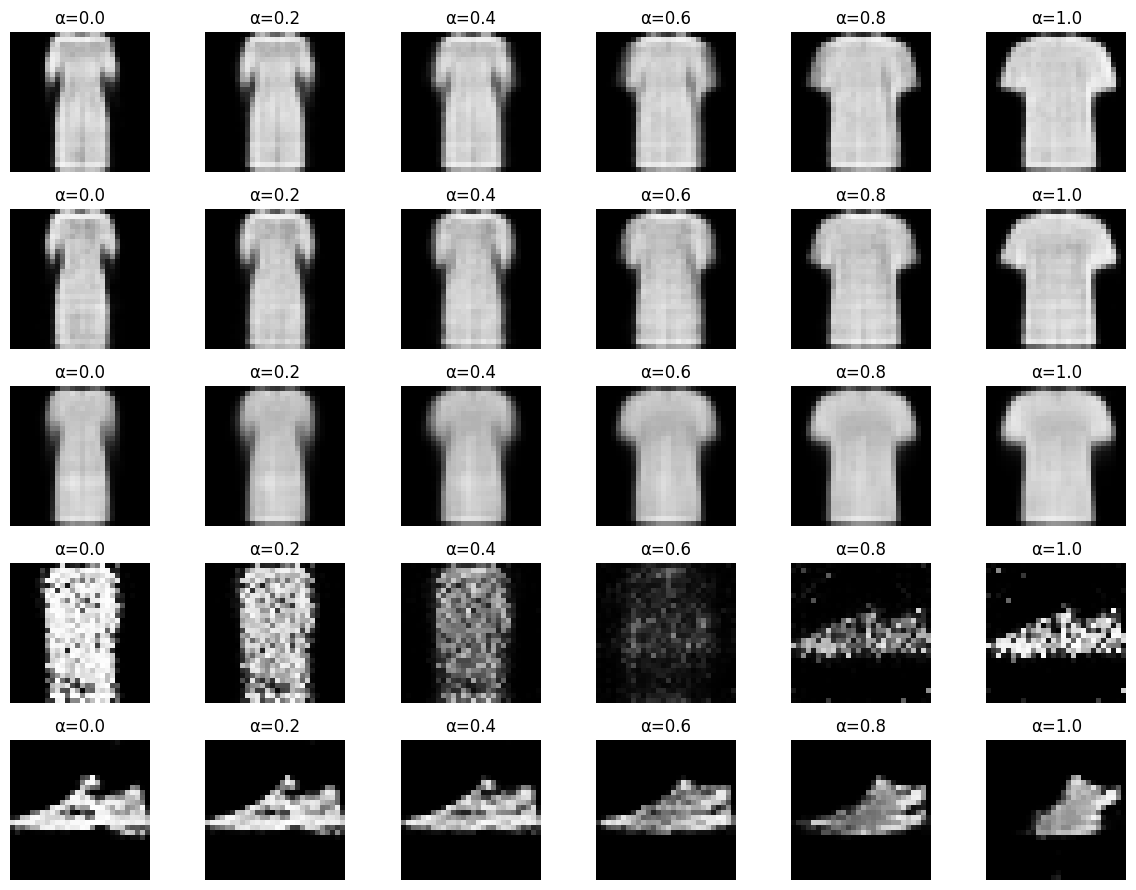

In [13]:
# Fig 4
@torch.no_grad()
def interpolation_grid():
    model_ae.eval()
    model_sae.eval()
    model_vae.eval()
    generator_gan.eval()
    generator_dcgan.eval()
    pair, _ = next(iter(test_loader))
    x_a = pair[0:1].to(device)
    x_b = pair[1:2].to(device)
    alphas_interp = torch.linspace(0,1,6,device=device)
    z_ae_a, z_ae_b = model_ae.encode(x_a), model_ae.encode(x_b)
    z_sae_a, z_sae_b = model_sae.encode(x_a), model_sae.encode(x_b)
    mu_a, _ = model_vae.encode(x_a)
    mu_b, _ = model_vae.encode(x_b)
    z_gan_a, z_gan_b = torch.randn(1,100,device=device), torch.randn(1,100,device=device)
    grids = []
    for a in alphas_interp:
        grids.append(("Vanilla AE", model_ae.decode((1-a)*z_ae_a+a*z_ae_b)))
    for a in alphas_interp:
        grids.append(("Sparse AE", model_sae.decode((1-a)*z_sae_a+a*z_sae_b)))
    for a in alphas_interp:
        grids.append(("VAE", model_vae.decode((1-a)*mu_a+a*mu_b)))
    for a in alphas_interp:
        grids.append(("Vanilla GAN", generator_gan((1-a)*z_gan_a+a*z_gan_b)))
    for a in alphas_interp:
        grids.append(("DCGAN", generator_dcgan((1-a)*z_gan_a+a*z_gan_b)))
    return grids, alphas_interp.cpu()

interp, alphas_interp = interpolation_grid()
fig, axes = plt.subplots(5,6,figsize=(12,9))
row_names = ["Vanilla AE","Sparse AE","VAE","Vanilla GAN","DCGAN"]
for r in range(5):
    for c in range(6):
        image = interp[r*6+c][1][0].detach().cpu()
        if r >= 3:
            image = (image + 1) / 2
        axes[r,c].imshow(image[0].clamp(0,1),cmap="gray",vmin=0,vmax=1)
        axes[r,c].set_title(f"α={alphas_interp[c]:.1f}")
        axes[r,c].axis("off")
    axes[r,0].set_ylabel(row_names[r])
plt.tight_layout()
plt.savefig(RESULTS_DIR / "figure4_latent_interpolation.png",dpi=200,bbox_inches="tight")
plt.show()

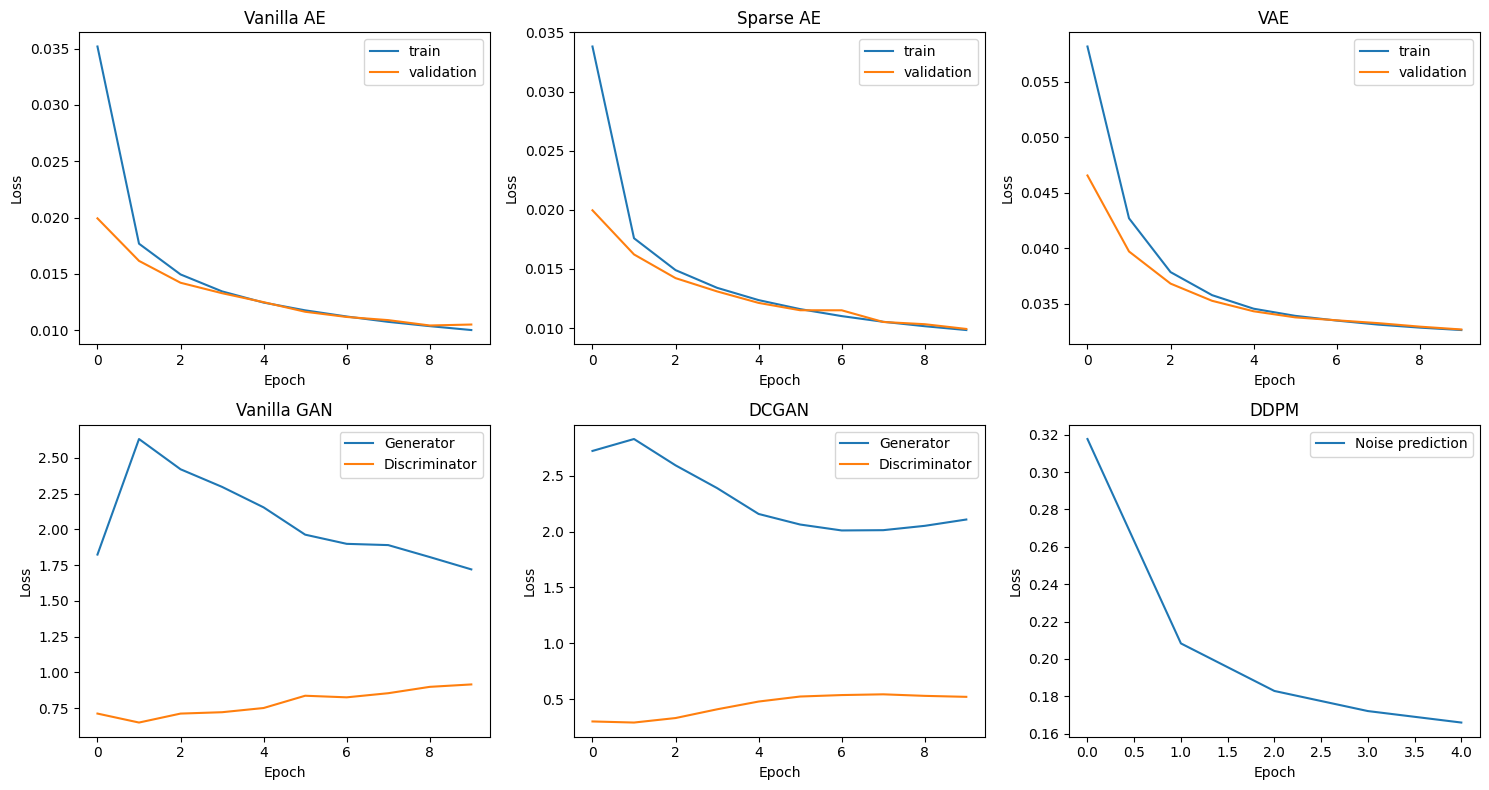

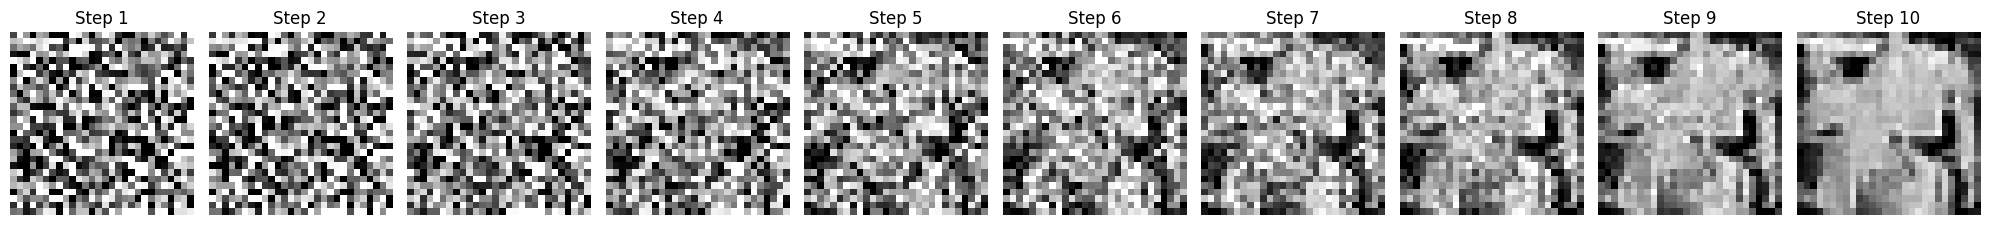

In [14]:
# Fig 5
fig, axes = plt.subplots(2,3,figsize=(15,8))
axes[0,0].plot(train_loss_ae,label="train")
axes[0,0].plot(val_loss_ae,label="validation")
axes[0,0].set_title("Vanilla AE")
axes[0,1].plot(train_loss_sae,label="train")
axes[0,1].plot(val_loss_sae,label="validation")
axes[0,1].set_title("Sparse AE")
axes[0,2].plot(train_loss_vae,label="train")
axes[0,2].plot(val_loss_vae,label="validation")
axes[0,2].set_title("VAE")
axes[1,0].plot(g_loss_history,label="Generator")
axes[1,0].plot(d_loss_history,label="Discriminator")
axes[1,0].set_title("Vanilla GAN")
axes[1,1].plot(g_loss_dcgan,label="Generator")
axes[1,1].plot(d_loss_dcgan,label="Discriminator")
axes[1,1].set_title("DCGAN")
axes[1,2].plot(train_loss_ddpm,label="Noise prediction")
axes[1,2].set_title("DDPM")
for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "figure5_loss_curves.png",dpi=200,bbox_inches="tight")
plt.show()

_, trajectory = sample_ddpm(1, save_trajectory=True)
fig, axes = plt.subplots(1,len(trajectory),figsize=(2*len(trajectory),2.5))
for i, x in enumerate(trajectory):
    img = ((x[0,0]+1)/2).clamp(0,1)
    axes[i].imshow(img,cmap="gray",vmin=0,vmax=1)
    axes[i].set_title(f"Step {i+1}")
    axes[i].axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "ddpm_denoising_trajectory.png",dpi=200,bbox_inches="tight")
plt.show()

In [20]:
# FID Score
from torchmetrics.image.fid import FrechetInceptionDistance
from tqdm.auto import tqdm
import time

fid_device = torch.device("cpu")
FID_SAMPLES = 256
FID_BATCH_SIZE = 32

def prepare_fid_images(images):
    images = images.detach().to(fid_device).clamp(0, 1)
    images = images.repeat(1, 3, 1, 1)
    images = F.interpolate(
        images,
        size=(299, 299),
        mode="bilinear",
        align_corners=False
    )
    return (images * 255).round().to(torch.uint8)

@torch.no_grad()
def calculate_fid(sample_function, model_name, n_samples=FID_SAMPLES, batch_size=FID_BATCH_SIZE):
    start_time = time.time()
    print(f"\n[{model_name}] Memulai perhitungan FID...")

    metric = FrechetInceptionDistance(
        feature=2048,
        normalize=False
    ).to(fid_device)

    real_images = []
    real_seen = 0

    with tqdm(total=n_samples, desc=f"{model_name} | Real images", unit="img") as bar:
        for images, _ in test_loader:
            remaining = n_samples - real_seen
            if remaining <= 0:
                break

            images = images[:remaining]
            real_images.append(prepare_fid_images(images))
            real_seen += images.size(0)
            bar.update(images.size(0))

    with tqdm(total=len(real_images), desc=f"{model_name} | Extracting real features", unit="batch") as bar:
        for images in real_images:
            metric.update(images, real=True)
            bar.update(1)

    generated_seen = 0

    with tqdm(total=n_samples, desc=f"{model_name} | Generated images", unit="img") as bar:
        while generated_seen < n_samples:
            n = min(batch_size, n_samples - generated_seen)
            generated = sample_function(n)
            metric.update(prepare_fid_images(generated), real=False)
            generated_seen += n
            bar.update(n)

    fid_value = float(metric.compute().item())
    elapsed = time.time() - start_time

    print(f"[{model_name}] FID: {fid_value:.4f} | Waktu: {elapsed:.1f} detik")
    return fid_value

fid_results = {}

fid_results["VAE"] = calculate_fid(
    lambda n: model_vae.decode(torch.randn(n, LATENT_DIM, device=device)),
    model_name="VAE"
)

fid_results["Vanilla GAN"] = calculate_fid(
    lambda n: ((generator_gan(torch.randn(n, GAN_LATENT_DIM, device=device)) + 1) / 2).clamp(0, 1),
    model_name="Vanilla GAN"
)

fid_results["DCGAN"] = calculate_fid(
    lambda n: ((generator_dcgan(torch.randn(n, GAN_LATENT_DIM, device=device)) + 1) / 2).clamp(0, 1),
    model_name="DCGAN"
)

fid_results["DDPM"] = calculate_fid(
    lambda n: sample_ddpm(n),
    model_name="DDPM"
)


[VAE] Memulai perhitungan FID...


VAE | Real images: 100%|██████████| 256/256 [00:00<00:00, 728.34img/s]
VAE | Extracting real features: 100%|██████████| 2/2 [00:59<00:00, 29.56s/batch]
VAE | Generated images: 100%|██████████| 256/256 [00:56<00:00,  4.56img/s]


[VAE] FID: 146.8837 | Waktu: 118.6 detik

[Vanilla GAN] Memulai perhitungan FID...


Vanilla GAN | Real images: 100%|██████████| 256/256 [00:00<00:00, 677.42img/s]
Vanilla GAN | Extracting real features: 100%|██████████| 2/2 [00:55<00:00, 27.74s/batch]
Vanilla GAN | Generated images: 100%|██████████| 256/256 [00:56<00:00,  4.56img/s]


[Vanilla GAN] FID: 219.0373 | Waktu: 116.7 detik

[DCGAN] Memulai perhitungan FID...


DCGAN | Real images: 100%|██████████| 256/256 [00:00<00:00, 931.85img/s]
DCGAN | Extracting real features: 100%|██████████| 2/2 [00:55<00:00, 27.56s/batch]
DCGAN | Generated images: 100%|██████████| 256/256 [00:56<00:00,  4.57img/s]


[DCGAN] FID: 103.9708 | Waktu: 114.4 detik

[DDPM] Memulai perhitungan FID...


DDPM | Real images: 100%|██████████| 256/256 [00:00<00:00, 778.35img/s]
DDPM | Extracting real features: 100%|██████████| 2/2 [00:33<00:00, 16.79s/batch]
DDPM | Generated images: 100%|██████████| 256/256 [00:29<00:00,  8.63img/s]


[DDPM] FID: 257.9966 | Waktu: 65.5 detik


In [55]:
# FID Score
fid_device = torch.device("cpu")
FID_SAMPLES = 256
FID_BATCH_SIZE = 32

def prepare_fid_images(images):
    images = images.detach().to(fid_device).clamp(0, 1)
    images = images.repeat(1, 3, 1, 1)

    images = F.interpolate(
        images,
        size=(299, 299),
        mode="bilinear",
        align_corners=False
    )

    return (images * 255).round().to(torch.uint8)

@torch.no_grad()
def calculate_fid(
    sample_function,
    model_name,
    n_samples=FID_SAMPLES,
    batch_size=FID_BATCH_SIZE
):
    start_time = time.time()
    print(f"\n[{model_name}] Memulai perhitungan FID...")

    metric = FrechetInceptionDistance(
        feature=2048,
        normalize=False
    ).to(fid_device)

    real_images = []
    real_seen = 0

    with tqdm(
        total=n_samples,
        desc=f"{model_name} | Real images",
        unit="img"
    ) as bar:
        for images, _ in test_loader:
            remaining = n_samples - real_seen

            if remaining <= 0:
                break

            images = images[:remaining]
            real_images.append(prepare_fid_images(images))

            real_seen += images.size(0)
            bar.update(images.size(0))

    if real_seen < n_samples:
        raise ValueError(
            f"Test set hanya menyediakan {real_seen} gambar, "
            f"kurang dari {n_samples} sampel yang diminta."
        )

    with tqdm(
        total=len(real_images),
        desc=f"{model_name} | Extracting real features",
        unit="batch"
    ) as bar:
        for images in real_images:
            metric.update(images, real=True)
            bar.update(1)

    generated_seen = 0

    with tqdm(
        total=n_samples,
        desc=f"{model_name} | Generated images",
        unit="img"
    ) as bar:
        while generated_seen < n_samples:
            n = min(
                batch_size,
                n_samples - generated_seen
            )

            generated = sample_function(n)

            metric.update(
                prepare_fid_images(generated),
                real=False
            )

            generated_seen += n
            bar.update(n)

    fid_value = float(metric.compute().item())
    elapsed = time.time() - start_time

    print(
        f"[{model_name}] FID: {fid_value:.4f} "
        f"| Waktu: {elapsed:.1f} detik"
    )

    return fid_value

fid_results = {}

fid_results["VAE"] = calculate_fid(
    lambda n: model_vae.decode(
        torch.randn(n, LATENT_DIM, device=device)
    ),
    model_name="VAE"
)

fid_results["Vanilla GAN"] = calculate_fid(
    lambda n: (
        (
            generator_gan(
                torch.randn(n, GAN_LATENT_DIM, device=device)
            ) + 1
        ) / 2
    ).clamp(0, 1),
    model_name="Vanilla GAN"
)

fid_results["DCGAN"] = calculate_fid(
    lambda n: (
        (
            generator_dcgan(
                torch.randn(n, GAN_LATENT_DIM, device=device)
            ) + 1
        ) / 2
    ).clamp(0, 1),
    model_name="DCGAN"
)

fid_results["DDPM"] = calculate_fid(
    lambda n: sample_ddpm(n),
    model_name="DDPM"
)

import numpy as np

fid_results["Vanilla AE"] = np.nan
fid_results["Sparse AE"] = np.nan

print("FID RESULTS")

for model_name in [
    "Vanilla AE",
    "Sparse AE",
    "VAE",
    "Vanilla GAN",
    "DCGAN",
    "DDPM"
]:
    score = fid_results[model_name]

    if np.isnan(score):
        print(f"{model_name}: N/A")
    else:
        print(f"{model_name}: {score:.4f}")


[VAE] Memulai perhitungan FID...


VAE | Real images: 100%|██████████| 256/256 [00:00<00:00, 1092.86img/s]
VAE | Extracting real features: 100%|██████████| 2/2 [00:29<00:00, 14.75s/batch]
VAE | Generated images: 100%|██████████| 256/256 [00:29<00:00,  8.78img/s]


[VAE] FID: 155.5867 | Waktu: 61.2 detik

[Vanilla GAN] Memulai perhitungan FID...


Vanilla GAN | Real images: 100%|██████████| 256/256 [00:00<00:00, 1097.81img/s]
Vanilla GAN | Extracting real features: 100%|██████████| 2/2 [00:27<00:00, 13.77s/batch]
Vanilla GAN | Generated images: 100%|██████████| 256/256 [00:30<00:00,  8.47img/s]


[Vanilla GAN] FID: 227.2360 | Waktu: 59.9 detik

[DCGAN] Memulai perhitungan FID...


DCGAN | Real images: 100%|██████████| 256/256 [00:00<00:00, 899.09img/s]
DCGAN | Extracting real features: 100%|██████████| 2/2 [00:25<00:00, 12.98s/batch]
DCGAN | Generated images: 100%|██████████| 256/256 [00:25<00:00,  9.91img/s]


[DCGAN] FID: 101.5889 | Waktu: 53.9 detik

[DDPM] Memulai perhitungan FID...


DDPM | Real images: 100%|██████████| 256/256 [00:00<00:00, 1774.73img/s]
DDPM | Extracting real features: 100%|██████████| 2/2 [00:26<00:00, 13.04s/batch]
DDPM | Generated images: 100%|██████████| 256/256 [00:28<00:00,  8.87img/s]


[DDPM] FID: 257.0736 | Waktu: 56.9 detik
FID RESULTS
Vanilla AE: N/A
Sparse AE: N/A
VAE: 155.5867
Vanilla GAN: 227.2360
DCGAN: 101.5889
DDPM: 257.0736


In [56]:
fid_ae = fid_results["Vanilla AE"]
fid_sae = fid_results["Sparse AE"]
fid_vae = fid_results["VAE"]
fid_gan = fid_results["Vanilla GAN"]
fid_dcgan = fid_results["DCGAN"]
fid_ddpm = fid_results["DDPM"]

In [57]:
model_ae.eval()
model_sae.eval()
model_vae.eval()
generator_gan.eval()
generator_dcgan.eval()
model_ddpm.eval()

latency_ae = measure_latency(lambda: model_ae(torch.randn(64,1,28,28,device=device)))
latency_sae = measure_latency(lambda: model_sae(torch.randn(64,1,28,28,device=device)))
latency_vae = measure_latency(lambda: model_vae(torch.randn(64,1,28,28,device=device)))
latency_gan = measure_latency(lambda: generator_gan(torch.randn(64,GAN_LATENT_DIM,device=device)))
latency_dcgan = measure_latency(lambda: generator_dcgan(torch.randn(64,GAN_LATENT_DIM,device=device)))

def ddpm_latency_fn():
    x = torch.randn(64,1,28,28,device=device)
    with torch.no_grad():
        for t in reversed(range(timesteps)):
            t_batch = torch.full((64,),t,device=device,dtype=torch.long)
            pred_noise = model_ddpm(x,t_batch)
            alpha_t, alpha_bar_t, beta_t = alphas[t], alpha_bars[t], betas[t]
            x = (x - ((1-alpha_t)/torch.sqrt(1-alpha_bar_t))*pred_noise) / torch.sqrt(alpha_t)
            if t > 0:
                x = x + torch.sqrt(beta_t)*torch.randn_like(x)
    return x
latency_ddpm = measure_latency(ddpm_latency_fn, warmup=1, runs=3)

comparison_df = pd.DataFrame([
    {"Model":"Vanilla AE","Latent dim":64,"Training time/epoch (s)":np.mean(time_ae),"Latency batch 64 (ms)":latency_ae,"Test MSE":mse_ae,"Test PSNR":psnr_ae,"Test SSIM":ssim_ae,"FID":fid_ae,"Training stability":"Stabil / konvergen"},
    {"Model":"Sparse AE","Latent dim":64,"Training time/epoch (s)":np.mean(time_sae),"Latency batch 64 (ms)":latency_sae,"Test MSE":mse_sae,"Test PSNR":psnr_sae,"Test SSIM":ssim_sae,"FID":fid_sae,"Training stability":"Stabil / konvergen"},
    {"Model":"VAE","Latent dim":64,"Training time/epoch (s)":np.mean(time_vae),"Latency batch 64 (ms)":latency_vae,"Test MSE":mse_vae,"Test PSNR":psnr_vae,"Test SSIM":ssim_vae,"FID":fid_vae,"Training stability":"Stabil / konvergen"},
    {"Model":"Vanilla GAN","Latent dim":100,"Training time/epoch (s)":np.mean(time_gan),"Latency batch 64 (ms)":latency_gan,"Test MSE":np.nan,"Test PSNR":np.nan,"Test SSIM":np.nan,"FID":fid_gan,"Training stability":"Rentang osilasi / mode collapse"},
    {"Model":"DCGAN","Latent dim":100,"Training time/epoch (s)":np.mean(time_dcgan),"Latency batch 64 (ms)":latency_dcgan,"Test MSE":np.nan,"Test PSNR":np.nan,"Test SSIM":np.nan,"FID":fid_dcgan,"Training stability":"Sensitif arsitektur"},
    {"Model":"DDPM","Latent dim":"28x28 image","Training time/epoch (s)":np.mean(time_ddpm),"Latency batch 64 (ms)":latency_ddpm,"Test MSE":np.nan,"Test PSNR":np.nan,"Test SSIM":np.nan,"FID":fid_ddpm,"Training stability":"Noise-prediction objective"}
])
comparison_df.to_csv(RESULTS_DIR / "comparison_metrics.csv", index=False)
metrics_df.to_csv(RESULTS_DIR / "reconstruction_metrics.csv", index=False)
comparison_df

,Model,Latent dim,Training time/epoch (s),Latency batch 64 (ms),Test MSE,Test PSNR,Test SSIM,FID,Training stability
0,Vanilla AE,64,4.443336,0.366394,0.010431,19.816664,0.752431,NaN,Stabil / konvergen
1,Sparse AE,64,3.346057,0.285529,0.009682,20.140327,0.761049,NaN,Stabil / konvergen
2,VAE,64,3.421959,0.276591,0.022667,16.446037,0.574969,155.586731,Stabil / konvergen
3,Vanilla GAN,100,5.245374,0.186785,NaN,NaN,NaN,227.235992,Rentang osilasi / mode collapse
4,DCGAN,100,36.227874,2.575439,NaN,NaN,NaN,101.588936,Sensitif arsitektur
5,DDPM,28x28 image,17.167856,164.374500,NaN,NaN,NaN,257.073578,Noise-prediction objective


In [59]:
# Validasi FID
assert np.isnan(fid_ae)
assert np.isnan(fid_sae)

assert all(
    np.isfinite(v)
    for v in [fid_vae, fid_gan, fid_dcgan, fid_ddpm]
)

display(comparison_df)
comparison_df.to_csv(
    RESULTS_DIR / "comparison_metrics.csv",
    index=False
)

metrics_df.to_csv(
    RESULTS_DIR / "reconstruction_metrics.csv",
    index=False
)

,Model,Latent dim,Training time/epoch (s),Latency batch 64 (ms),Test MSE,Test PSNR,Test SSIM,FID,Training stability
0,Vanilla AE,64,4.443336,0.366394,0.010431,19.816664,0.752431,NaN,Stabil / konvergen
1,Sparse AE,64,3.346057,0.285529,0.009682,20.140327,0.761049,NaN,Stabil / konvergen
2,VAE,64,3.421959,0.276591,0.022667,16.446037,0.574969,155.586731,Stabil / konvergen
3,Vanilla GAN,100,5.245374,0.186785,NaN,NaN,NaN,227.235992,Rentang osilasi / mode collapse
4,DCGAN,100,36.227874,2.575439,NaN,NaN,NaN,101.588936,Sensitif arsitektur
5,DDPM,28x28 image,17.167856,164.374500,NaN,NaN,NaN,257.073578,Noise-prediction objective
